# Modelos de PLN
## Sistema Inteligente de Clasificación de Reclamos contra Movistar Perú


**Entrada:** `reclamos.csv` (columnas: `id`, `texto`, `texto_limpio`, `categoria`, `fuente`, `fecha`).

**Técnicas implementadas (mínimo 3 obligatorias):**
1. **Clasificación de texto** – TF-IDF + Naive Bayes y Regresión Logística (materia reclamable).
2. **Análisis de sentimiento** – pysentimiento (RoBERTuito, preentrenado en español).
3. **Topic Modeling** – NMF sobre TF-IDF para detectar temas frecuentes.
4. *(Opcional)* NER y n-gramas con spaCy.

**Salidas:** modelos guardados (`clasificador.pkl`, `vectorizador_tfidf.pkl`), `reclamos_con_sentimiento.csv`, métricas y este notebook documentado.

In [72]:
!pip install -q pysentimiento

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, accuracy_score,
                             f1_score, confusion_matrix)
from sklearn.decomposition import NMF

from pysentimiento import create_analyzer
from wordcloud import WordCloud

RANDOM_STATE = 42
sn_style = 'whitegrid'
sns.set_style(sn_style)
print('Librerías cargadas correctamente')

Librerías cargadas correctamente


## 1. Carga del dataset
Subimos el archivo `reclamos.csv`

In [73]:
from google.colab import files

uploaded = files.upload()   # selecciona reclamos.csv



df = pd.read_csv('reclamos.csv')
df["texto_limpio"] = df["texto"]
print(f'Reclamos cargados: {len(df)}')
df.head()

Saving reclamos.csv to reclamos (5).csv
Reclamos cargados: 146


,id,texto,texto_limpio,categoria,sentimiento,fuente,fecha,tipo_dato,url_fuente,estado_etiqueta
0,1,"Movistar me enyucó una deuda de 1,370 soles po...","Movistar me enyucó una deuda de 1,370 soles po...","Incumplimiento de condiciones contractuales, o...",NaN,reddit,2026-06-04,real_pendiente_verificacion,https://www.reddit.com/r/PERU/comments/1twc0zt...,pendiente_revision_manual
1,2,Hace un tiempo hubo un problema donde no tenía...,Hace un tiempo hubo un problema donde no tenía...,Facturación y cobro,NaN,reddit,2024-02-20,real_pendiente_verificacion,https://www.reddit.com/r/Lima_Peru/comments/1a...,pendiente_revision_manual
2,3,"Yo tuve un servicio de internet fijo, intenté ...","Yo tuve un servicio de internet fijo, intenté ...",Facturación y cobro,NaN,reddit,2024-02-20,real_pendiente_verificacion,https://www.reddit.com/r/Lima_Peru/comments/1a...,pendiente_revision_manual
3,4,Le di de baja el jueves y no paran de llamar (...,Le di de baja el jueves y no paran de llamar (...,Falta de ejecución de baja o suspensión del se...,NaN,reddit,2024-08-24,real_pendiente_verificacion,https://www.reddit.com/r/Lima_Peru/comments/1f...,pendiente_revision_manual
4,5,"Yo hice igual, solo que no lo cancelaron solo ...","Yo hice igual, solo que no lo cancelaron solo ...",Falta de ejecución de baja o suspensión del se...,NaN,reddit,2024-08-24,real_pendiente_verificacion,https://www.reddit.com/r/Lima_Peru/comments/1f...,pendiente_revision_manual


In [74]:
# Verificación rápida de las columnas esperadas
columnas_esperadas = ['id', 'texto', 'texto_limpio', 'categoria', 'fuente', 'fecha']
faltantes = [c for c in columnas_esperadas if c not in df.columns]
print('Columnas faltantes:', faltantes if faltantes else 'ninguna')
print('Nulos en texto_limpio:', df['texto_limpio'].isna().sum())
df['categoria'].value_counts()

Columnas faltantes: ninguna
Nulos en texto_limpio: 0


,count
categoria,
Calidad e idoneidad en la prestación del servicio,16
Falta de ejecución de baja o suspensión del servicio,15
Facturación y cobro,15
"Incumplimiento de condiciones contractuales, ofertas y promociones",14
Falta de servicio,13
Contratación no solicitada,13
Portabilidad,12
"Instalación, activación o traslado del servicio",12
Recargas,12


## 2. Exploración inicial de los datos
Antes de modelar, revisamos la distribución de categorías para detectar posible desbalance de clases (influye en la elección del modelo y en las métricas).

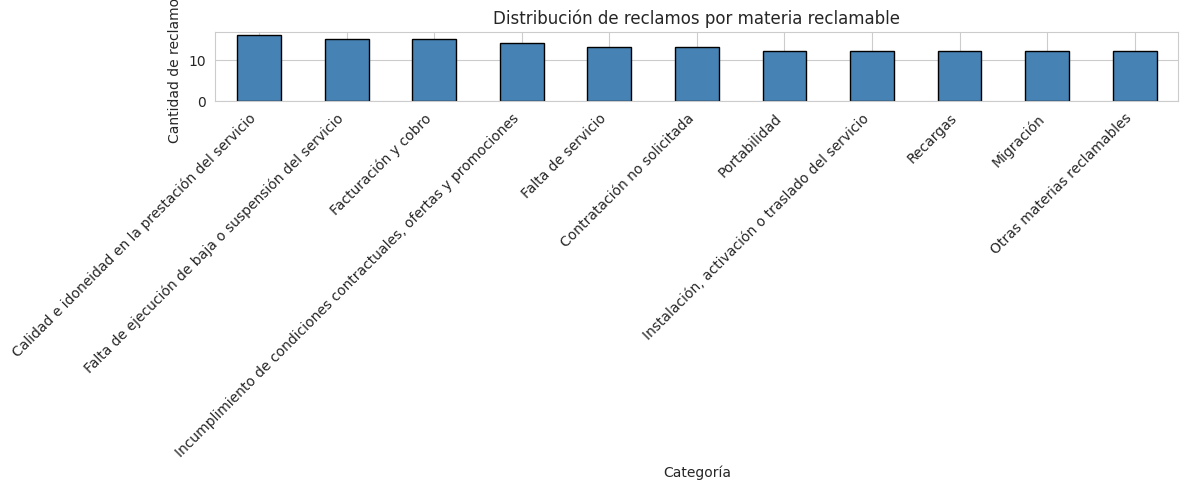

categoria
Calidad e idoneidad en la prestación del servicio                     0.110
Falta de ejecución de baja o suspensión del servicio                  0.103
Facturación y cobro                                                   0.103
Incumplimiento de condiciones contractuales, ofertas y promociones    0.096
Falta de servicio                                                     0.089
Contratación no solicitada                                            0.089
Portabilidad                                                          0.082
Instalación, activación o traslado del servicio                       0.082
Recargas                                                              0.082
Migración                                                             0.082
Otras materias reclamables                                            0.082
Name: proportion, dtype: float64


In [75]:
plt.figure(figsize=(12, 5))
df['categoria'].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Distribución de reclamos por materia reclamable')
plt.ylabel('Cantidad de reclamos')
plt.xlabel('Categoría')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(df['categoria'].value_counts(normalize=True).round(3))

## 3. TÉCNICA 1 – Clasificación de texto (TF-IDF + Naive Bayes / Regresión Logística)

**¿Qué hace?** Convierte cada reclamo en una bolsa de pesos TF-IDF (importancia de cada palabra respecto al corpus) y entrena dos clasificadores para predecir la materia reclamable.

**¿Por qué TF-IDF?** Da más peso a las palabras discriminativas de cada categoría (p. ej. "factura", "cobraron", "señal") y menos a palabras comunes.

**Métricas:** accuracy y, sobre todo, **F1 ponderado** y *classification report* por clase, porque las categorías están desbalanceadas.

In [76]:
# División entrenamiento / prueba (80/20), estratificada por categoría
X = df['texto_limpio'].fillna('')
y = df['categoria']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f'Train: {len(X_train)} | Test: {len(X_test)}')

Train: 116 | Test: 30


In [78]:
# Vectorización TF-IDF (aseguramos su definición para evitar NameError)
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Modelo 1: Naive Bayes Multinomial (línea base clásica para texto)
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)
y_pred_nb = nb.predict(X_test_tfidf)

# Modelo 2: Regresión Logística (class_weight='balanced' para compensar desbalance)
lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train_tfidf, y_train)
y_pred_lr = lr.predict(X_test_tfidf)

desempeno = {
    'Naive Bayes':          {'acc': accuracy_score(y_test, y_pred_nb),
                             'f1': f1_score(y_test, y_pred_nb, average='weighted')},
    'Regresión Logística':  {'acc': accuracy_score(y_test, y_pred_lr),
                             'f1': f1_score(y_test, y_pred_lr, average='weighted')},
}
for m, mts in desempeno.items():
    print(f'{m:>22} | Accuracy: {mts["acc"]:.3f} | F1 (ponderado): {mts["f1"]:.3f}')

           Naive Bayes | Accuracy: 0.400 | F1 (ponderado): 0.336
   Regresión Logística | Accuracy: 0.567 | F1 (ponderado): 0.536


In [79]:
# Reporte detallado del mejor modelo (el de mayor F1)
mejor = max(desempeno, key=lambda m: desempeno[m]['f1'])
y_pred_mejor = y_pred_lr if mejor.startswith('Regresión') else y_pred_nb
print(f'Mejor modelo: {mejor}\n')
print(classification_report(y_test, y_pred_mejor))

Mejor modelo: Regresión Logística

                                                                    precision    recall  f1-score   support

                 Calidad e idoneidad en la prestación del servicio       0.40      0.67      0.50         3
                                        Contratación no solicitada       0.50      0.33      0.40         3
                                               Facturación y cobro       0.33      0.33      0.33         3
              Falta de ejecución de baja o suspensión del servicio       0.67      0.67      0.67         3
                                                 Falta de servicio       0.50      0.67      0.57         3
Incumplimiento de condiciones contractuales, ofertas y promociones       0.00      0.00      0.00         3
                   Instalación, activación o traslado del servicio       0.67      0.67      0.67         3
                                                         Migración       0.50      1.00      0.67   

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


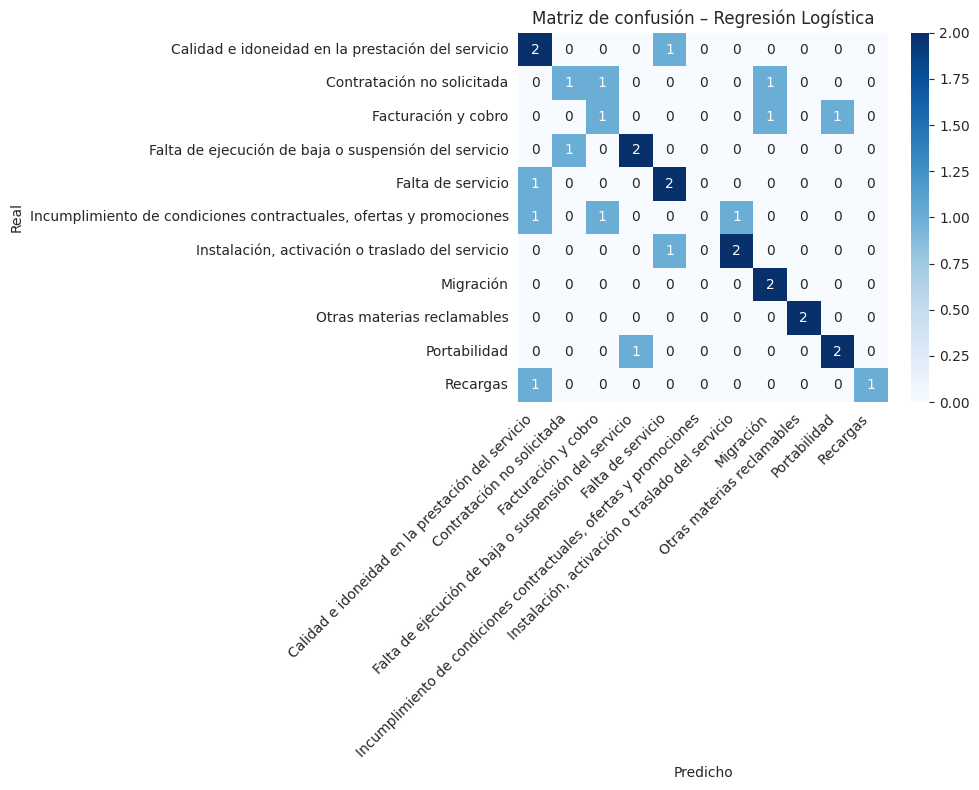

In [80]:
# Matriz de confusión del mejor modelo
cm = confusion_matrix(y_test, y_pred_mejor)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=sorted(y.unique()), yticklabels=sorted(y.unique()))
plt.title(f'Matriz de confusión – {mejor}')
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

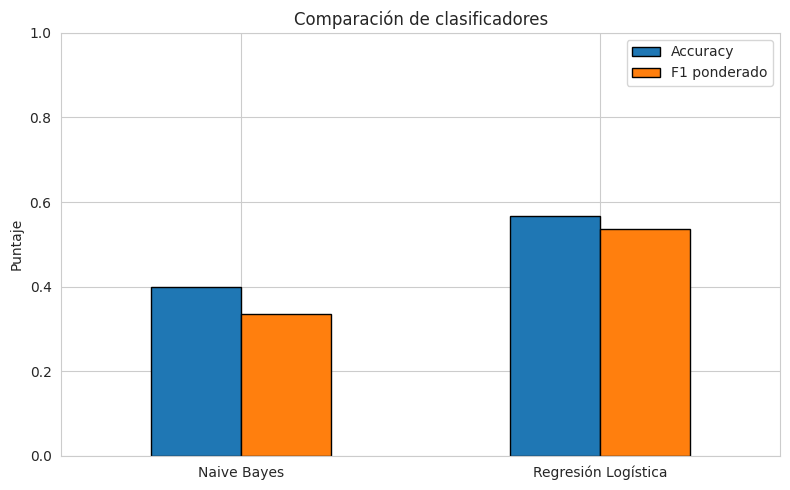

In [81]:
# Comparación gráfica de modelos
comp = pd.DataFrame(desempeno).T
comp.plot(kind='bar', figsize=(8, 5), edgecolor='black')
plt.title('Comparación de clasificadores')
plt.ylabel('Puntaje')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(['Accuracy', 'F1 ponderado'])
plt.tight_layout()
plt.show()

## 4. TÉCNICA 2 – Análisis de sentimiento

**¿Qué hace?** Usa **RoBERTuito** (RoBERTa entrenado en tweets en español, vía la librería `pysentimiento`) para asignar a cada reclamo una polaridad: **Positivo / Neutro / Negativo**.

**¿Por qué RoBERTuito y no un léxico?** Es un modelo neuronal contextual: capta ironías y matices del español informal típico de redes sociales, mucho mejor que listas de palabras positivas/negativas.

> Nota: si el volumen es grande, esta celda tarda varios minutos. Colab la acelera automáticamente si activas GPU (Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU).

In [82]:
# Inicializamos el analizador usando la función correcta de pysentimiento
analyzer = create_analyzer(task="sentiment", lang="es")

# Ejemplo rápido de prueba
ejemplo = 'Llevo 3 semanas reclamando y Movistar sigue cobrándome un servicio que no funciona, pésima atención'
print('Ejemplo →', analyzer.predict(ejemplo).output)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Ejemplo → NEG


In [83]:
# Aplicar a todo el dataset (puede tardar varios minutos)
df['sentimiento'] = (
    df['texto_limpio'].fillna('')
      .apply(lambda t: analyzer.predict(t).output)
      .map({'POS': 'Positivo', 'NEU': 'Neutro', 'NEG': 'Negativo'})
)
df['sentimiento'].value_counts()

,count
sentimiento,
Negativo,114
Neutro,32


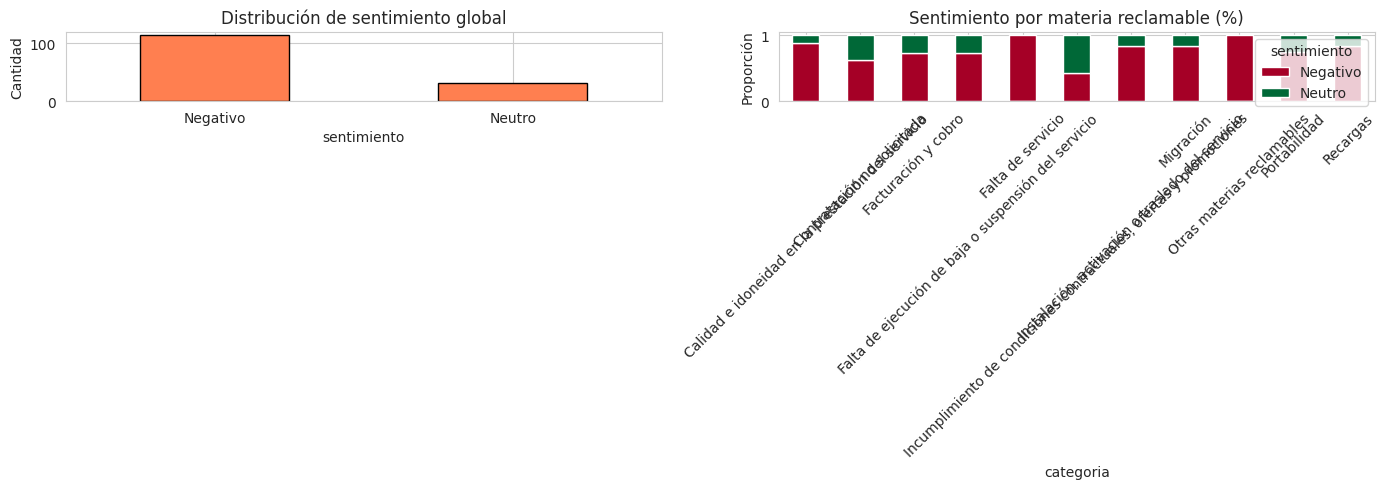

In [84]:
# Sentimiento global y sentimiento por categoría de reclamo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['sentimiento'].value_counts().plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Distribución de sentimiento global')
axes[0].set_ylabel('Cantidad')
axes[0].tick_params(axis='x', rotation=0)

ct = pd.crosstab(df['categoria'], df['sentimiento'], normalize='index')
ct.plot(kind='bar', stacked=True, ax=axes[1], colormap='RdYlGn')
axes[1].set_title('Sentimiento por materia reclamable (%)')
axes[1].set_ylabel('Proporción')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [85]:
# Validación manual: muestra aleatoria para revisar calidad del sentimiento
muestra = df[['texto', 'categoria', 'sentimiento']].sample(10, random_state=RANDOM_STATE)
for _, row in muestra.iterrows():
    print(f'[{row.sentimiento}] ({row.categoria})\n  {row.texto[:150]}...\n')

[Negativo] (Recargas)
  Compré un paquete de datos Movistar y no se activó aunque recibí mensaje de confirmación....

[Negativo] (Otras materias reclamables)
  La central telefónica me corta antes de que pueda registrar una queja formal....

[Neutro] (Falta de ejecución de baja o suspensión del servicio)
  El asesor aseguró que mi línea se desactivaría el viernes, llegó el lunes y todavía está activa....

[Neutro] (Facturación y cobro)
  El descuento prometido no apareció en el recibo y Movistar quiere que pague el monto total antes de reclamar....

[Negativo] (Falta de ejecución de baja o suspensión del servicio)
  Quise cancelar el servicio hogar y me pasaron de asesor en asesor sin registrar la solicitud....

[Negativo] (Calidad e idoneidad en la prestación del servicio)
  Pagué un plan supuestamente de alta velocidad y la conexión de Movistar es inestable, se cae por segundos constantemente....

[Negativo] (Instalación, activación o traslado del servicio)
  Solicité instalar intern

## 5. TÉCNICA 3 – Topic Modeling (NMF sobre TF-IDF)

**¿Qué hace?** La factorización de matrices no negativas (NMF) agrupa las palabras en *tópicos* latentes: cada reclamo es una mezcla de tópicos y cada tópico es un conjunto de palabras frecuentes. Permite descubrir **temas frecuentes** sin supervisión.

**¿Por qué NMF y no LDA?** Con documentos cortos (tweets/comentarios) y representación TF-IDF, NMF suele producir tópicos más estables y legibles. Se prueba con 5 tópicos y se ajusta según coherencia.

In [86]:
# Definimos una lista básica de stop words en español para limpiar los tópicos
stop_words_es = [
    'el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'de', 'del', 'al', 'y', 'o', 'no', 'si', 'sí',
    'en', 'para', 'por', 'con', 'sin', 'sobre', 'tras', 'hasta', 'desde', 'durante', 'que', 'qué', 'como',
    'me', 'te', 'se', 'nos', 'le', 'les', 'lo', 'la', 'lo', 'mi', 'mis', 'tu', 'tus', 'su', 'sus',
    'este', 'esta', 'estos', 'estas', 'ese', 'esa', 'esos', 'esas', 'aquel', 'aquella', 'aquellos', 'aquellas',
    'yo', 'tú', 'él', 'ella', 'nosotros', 'vosotros', 'ellos', 'ellas', 'me', 'mi', 'conmigo', 'ti', 'contigo',
    'es', 'son', 'era', 'eran', 'fue', 'fueron', 'ser', 'estar', 'tengo', 'tiene', 'tienen', 'hacer', 'hace', 'hacen',
    'pero', 'ya', 'muy', 'más', 'todo', 'todos', 'toda', 'todas', 'otro', 'otra', 'otros', 'otras', 'solo', 'sólo',
    'bien', 'mal', 'muy', 'mucho', 'poco', 'así', 'donde', 'cuando', 'quien', 'quienes', 'cual', 'cuales',
    'movistar', 'servicio', 'cliente', 'atención', 'reclamo', 'reclamar', 'hace', 'días', 'meses', 'semanas'
]

# TF-IDF para tópicos filtrando stop words en español
tfidf_topics = TfidfVectorizer(max_features=1000, ngram_range=(1, 2), min_df=2, stop_words=stop_words_es)
X_topics = tfidf_topics.fit_transform(df['texto'].fillna(''))

n_topicos = 5
nmf = NMF(n_components=n_topicos, max_iter=1000, random_state=RANDOM_STATE)
W = nmf.fit_transform(X_topics)          # matriz reclamos x tópicos
terminos = tfidf_topics.get_feature_names_out()

for i, componente in enumerate(nmf.components_):
    top = componente.argsort()[::-1][:12]
    print(f'Tópico {i+1}: ' + ', '.join(terminos[j] for j in top))

Tópico 1: plan, nadie, llegó, contraté, migrar, migración, app, 90, conexión, recibo, pagué, después
Tópico 2: portabilidad, operador, línea, señal, cambio operador, después, cambio, hice, todavía, llamadas, negocio, ayer
Tópico 3: internet, cable, hay, ni, solicité, señal, va, dice, técnico, router, horas, aparece
Tópico 4: nunca, paquete, cuenta, recarga, renovar, saldo, autoricé, figura, número, contrato, figura paquete, apareció
Tópico 5: pedí, mes, siguen, pago, recibos, baja, porque, internet, visita, cobrar, pospago, prepago


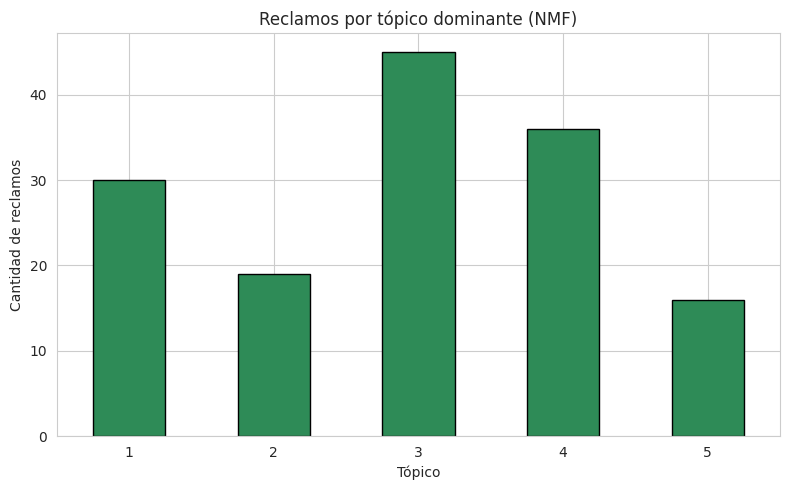

In [87]:
# Tópico dominante por reclamo y frecuencia de cada tópico
df['topico_dominante'] = W.argmax(axis=1) + 1

plt.figure(figsize=(8, 5))
df['topico_dominante'].value_counts().sort_index().plot(kind='bar', color='seagreen', edgecolor='black')
plt.title('Reclamos por tópico dominante (NMF)')
plt.xlabel('Tópico')
plt.ylabel('Cantidad de reclamos')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. (Opcional) NER y n-gramas con spaCy
Extracción de entidades (organizaciones, montos, servicios) y frases más frecuentes. Útil para el análisis del informe y el rubro de innovación.

In [88]:
!python -m spacy download es_core_news_sm
import spacy
from collections import Counter

nlp = spacy.load('es_core_news_sm')

# NER sobre una muestra (procesar todo el dataset es lento)
muestra_ner = df['texto_limpio'].fillna('').sample(min(200, len(df)), random_state=RANDOM_STATE)
ents = [ent.text for doc in nlp.pipe(muestra_ner) for ent in doc.ents if ent.label_ in ('ORG', 'MONEY', 'PRODUCT')]
print('Entidades más frecuentes:', Counter(ents).most_common(15))

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 24.2 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Entidades más frecuentes: [('Movistar', 26), ('plan Movistar', 1), ('Mi Movistar', 1), ('Bitel', 1), ('app Movistar', 1), ('agencia Movistar de Parodi', 1), ('app', 1), ('pra', 1), ('Tuve Movistar', 1), ('línea Movistar', 1)]


In [89]:
# N-gramas más frecuentes del corpus completo usando la columna 'texto'
from sklearn.feature_extraction.text import CountVectorizer

# Reducimos min_df a 2 para que no elimine todas las combinaciones en este dataset pequeño
cv = CountVectorizer(ngram_range=(2, 3), min_df=2, max_features=500, stop_words=stop_words_es)
bow = cv.fit_transform(df['texto'].fillna(''))
sumas = bow.sum(axis=0)
frecuencias = sorted(zip(cv.get_feature_names_out(), np.asarray(sumas)[0]),
                     key=lambda x: -x[1])[:20]
for frase, n in frecuencias:
    print(f'{n:>5}  {frase}')

    2  69 90
    2  activó línea
    2  app sigue
    2  banca móvil
    2  cada vez
    2  cambio operador
    2  da fecha
    2  dijeron podían
    2  figura paquete
    2  internet ni
    2  llegó mensaje
    2  línea pospago
    2  ningún lado
    2  nunca apareció
    2  nunca pedí
    2  paquete datos
    2  pedí ahora
    2  plan caro
    2  portar número
    2  sigue mostrando


## 7. Nube de palabras (apoyo visual para el informe)

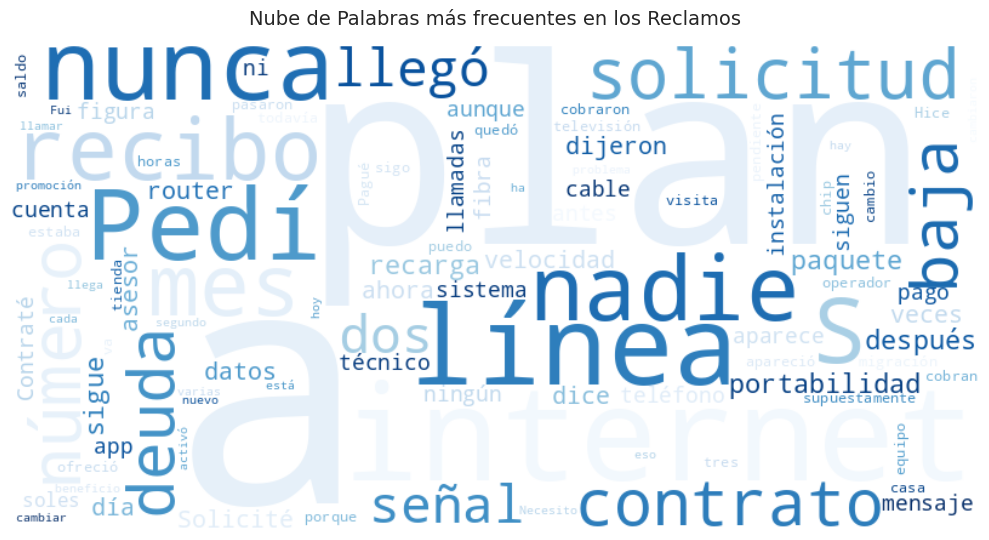

In [90]:
# Generación de la Nube de Palabras (Word Cloud)
texto_completo = ' '.join(df['texto'].fillna('').astype(str))

# Creamos la nube de palabras con un diseño limpio y profesional
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    colormap='Blues',      # Tonalidades azules corporativas de Movistar
    stopwords=set(stop_words_es),
    max_words=100,
    random_state=RANDOM_STATE
).generate(texto_completo)

plt.figure(figsize=(10, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Nube de Palabras más frecuentes en los Reclamos', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

## 8. Guardado de modelos y dataset final
Los archivos `.pkl` los consumirá la Persona C en la aplicación Streamlit para predecir en tiempo real. El clasificador y el vectorizador deben guardarse siempre juntos (el vectorizador transforma el texto nuevo con el mismo vocabulario).

In [ ]:
# Guardar el mejor clasificador y su vectorizador
if mejor.startswith('Regresión'):
    joblib.dump(lr, 'clasificador.pkl')
else:
    joblib.dump(nb, 'clasificador.pkl')
joblib.dump(tfidf, 'vectorizador_tfidf.pkl')

# Dataset final con sentimiento y tópico para la app Streamlit y el dashboard
df.to_csv('reclamos_con_sentimiento.csv', index=False)

# Tabla comparativa de modelos (para el informe final)
tabla = pd.DataFrame(desempeno).T.round(3)
tabla.to_csv('comparacion_modelos.csv')
print(tabla)
print()
print('Archivos generados: clasificador.pkl, vectorizador_tfidf.pkl, reclamos_con_sentimiento.csv, comparacion_modelos.csv')

                       acc     f1
Naive Bayes          0.467  0.431
Regresión Logística  0.500  0.457

Archivos generados: clasificador.pkl, vectorizador_tfidf.pkl, reclamos_con_sentimiento.csv, comparacion_modelos.csv


In [ ]:
# Descargar los archivos generados
for archivo in ['clasificador.pkl', 'vectorizador_tfidf.pkl',
                'reclamos_con_sentimiento.csv', 'comparacion_modelos.csv']:
    files.download(archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [92]:
# ================================================================
# SECCIÓN 8.5 — SALIDAS PARA LAS CONCLUSIONES Y EL INFORME FINAL
# Requiere haber ejecutado: clasificación (3), sentimiento (4),
# tópicos (5), NER/n-gramas (6)
# ================================================================
from sklearn.metrics import classification_report
from collections import Counter
import pandas as pd

separador = "=" * 70

# ---------- 1) TAMAÑO Y DISTRIBUCIÓN DEL DATASET ----------
print(separador); print("1) TAMAÑO Y DISTRIBUCIÓN DEL DATASET"); print(separador)
print(f"Total de reclamos: {len(df)}  (mínimo exigido: 500)")
if 'fuente' in df.columns:
    print("Por fuente:", df['fuente'].value_counts().to_dict())
if 'fecha' in df.columns:
    # Convertimos a datetime manejando los errores y valores nulos para evitar el TypeError
    fechas_validas = pd.to_datetime(df['fecha'], errors='coerce').dropna()
    if not fechas_validas.empty:
        print(f"Rango de fechas: {fechas_validas.min().strftime('%Y-%m-%d')} → {fechas_validas.max().strftime('%Y-%m-%d')}")
    else:
        print("Rango de fechas: No hay fechas válidas")
dist = pd.DataFrame({'conteo': df['categoria'].value_counts(),
                     '%': (df['categoria'].value_counts(normalize=True) * 100).round(1)})
print(dist)
print(f"\nClase minoritaria: {dist['conteo'].idxmin()} ({dist['conteo'].min()} ejemplos)")
print(f"Clase mayoritaria: {dist['conteo'].idxmax()} ({dist['conteo'].max()} ejemplos)")
print(f"Ratio de desbalance: {dist['conteo'].max() / dist['conteo'].min():.1f}x")

# ---------- 2) TABLA COMPARATIVA DE CLASIFICADORES ----------
print(separador); print("2) COMPARACIÓN NB vs REGRESIÓN LOGÍSTICA"); print(separador)
print(tabla)
print(f"\nMejor modelo seleccionado: {mejor}")
dif_f1 = abs(tabla['f1'].iloc[0] - tabla['f1'].iloc[1])
print(f"Diferencia de F1 entre modelos: {dif_f1:.3f}")

# ---------- 3) MÉTRICAS POR CATEGORÍA ----------
print(separador); print("3) CLASSIFICATION REPORT POR CATEGORÍA"); print(separador)
reporte = pd.DataFrame(classification_report(
    y_test, y_pred_mejor, output_dict=True, zero_division=0)).T
print(reporte.round(3))
solo_clases = reporte.drop(index=['accuracy', 'macro avg', 'weighted avg'], errors='ignore')
print("\nCategorías de PEOR a MEJOR F1:")
print(solo_clases.sort_values('f1-score')[['precision', 'recall', 'f1-score', 'support']].round(3))

# ---------- 4) ANÁLISIS DE ERRORES (matriz de confusión explicada) ----------
print(separador); print("4) PARES REAL→PREDICHO MÁS FRECUENTES"); print(separador)
try:
    textos_test = X_test_raw          # si seguiste usando el texto original en el split
except NameError:
    textos_test = X_test
errores = pd.DataFrame({'real': y_test.values,
                        'pred': y_pred_mejor,
                        'texto': pd.Series(textos_test).values})
pares = (errores[errores.real != errores.pred]
         .groupby(['real', 'pred']).size().sort_values(ascending=False))
print(pares.head(10))
print("\nEjemplo de cada uno de los 3 errores más frecuentes:")
for (r, p), n in pares.head(3).items():
    ej = errores[(errores.real == r) & (errores.pred == p)]['texto'].iloc[0]
    print(f"\n[{n} casos] real='{r}' → predicho='{p}'\n  %{str(ej)[:200]}%")

# ---------- 5) SENTIMIENTO GLOBAL Y POR CATEGORÍA ----------
print(separador); print("5) SENTIMIENTO"); print(separador)
print(df['sentimiento'].value_counts())
print((df['sentimiento'].value_counts(normalize=True) * 100).round(1).astype(str) + '%')
neg = pd.crosstab(df['categoria'], df['sentimiento'], normalize='index')['Negativo'] * 100
print("\nTop 5 categorías con mayor % de sentimiento NEGATIVO:")
print(neg.sort_values(ascending=False).head(5).round(1).astype(str) + '%')

# ---------- 6) EMOCIONES (técnica que faltaba al documento) ----------
print(separador); print("6) EMOCIÓN PREDOMINANTE (RoBERTuito)"); print(separador)
emotion_analyzer = create_analyzer(task="emotion", lang="es")
df['emocion'] = df['texto_limpio'].fillna('').apply(
    lambda t: emotion_analyzer.predict(t).output if len(t) > 0 else 'others')
print(df['emocion'].value_counts())
emo_cat = pd.crosstab(df['categoria'], df['emocion'])
print("\nEmoción dominante por categoría:")
print(emo_cat.idxmax(axis=1))

# ---------- 7) TÓPICOS NMF ----------
print(separador); print("7) TÓPICOS NMF (10 palabras clave por tópico)"); print(separador)
tabla_topicos = pd.DataFrame(
    {f'Tópico {i+1}': [terminos[j] for j in c.argsort()[::-1][:10]]
     for i, c in enumerate(nmf.components_)})
print(tabla_topicos)
print("\nReclamos por tópico dominante:")
print(df['topico_dominante'].value_counts().sort_index())

# ---------- 8) ENTIDADES Y N-GRAMAS ----------
print(separador); print("8) ENTIDADES Y FRASES FRECUENTES"); print(separador)
print("Top 15 entidades (ORG/MONEY/PRODUCT):")
print(pd.DataFrame(Counter(ents).most_common(15), columns=['entidad', 'frecuencia']))
print("\nTop 20 bigramas/trigramas:")
print(pd.DataFrame(frecuencias, columns=['frase', 'frecuencia']))

# ---------- 9) MUESTRA PARA TU VALIDACIÓN MANUAL DEL SENTIMIENTO ----------
print(separador); print("9) MUESTRA PARA VALIDACIÓN MANUAL (30 reclamos)"); print(separador)
muestra_val = df[['texto', 'sentimiento']].sample(30, random_state=7)
for i, (_, r) in enumerate(muestra_val.iterrows(), 1):
    print(f"{i:>2}. [{r.sentimiento}] {str(r.texto)[:180]}")

# ---------- 10) GUARDAR DATASET FINAL AMPLIADO ----------
df.to_csv('reclamos_con_sentimiento.csv', index=False)
print(separador)
print("Archivo actualizado: reclamos_con_sentimiento.csv (ahora incluye 'emocion')")

1) TAMAÑO Y DISTRIBUCIÓN DEL DATASET
Total de reclamos: 146  (mínimo exigido: 500)
Por fuente: {'sintetico': 132, 'reddit': 14}
Rango de fechas: 2022-04-02 → 2026-08-28
                                                    conteo     %
categoria                                                       
Calidad e idoneidad en la prestación del servicio       16  11.0
Falta de ejecución de baja o suspensión del ser...      15  10.3
Facturación y cobro                                     15  10.3
Incumplimiento de condiciones contractuales, of...      14   9.6
Falta de servicio                                       13   8.9
Contratación no solicitada                              13   8.9
Portabilidad                                            12   8.2
Instalación, activación o traslado del servicio         12   8.2
Recargas                                                12   8.2
Migración                                               12   8.2
Otras materias reclamables                         

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

emocion
others    118
anger      28
Name: count, dtype: int64

Emoción dominante por categoría:
categoria
Calidad e idoneidad en la prestación del servicio                      anger
Contratación no solicitada                                            others
Facturación y cobro                                                   others
Falta de ejecución de baja o suspensión del servicio                  others
Falta de servicio                                                     others
Incumplimiento de condiciones contractuales, ofertas y promociones    others
Instalación, activación o traslado del servicio                       others
Migración                                                             others
Otras materias reclamables                                            others
Portabilidad                                                          others
Recargas                                                              others
dtype: object
7) TÓPICOS NMF (10 palabras clave

In [93]:
# ================================================================
# SECCIÓN 9 — CONCLUSIONES Y RECOMENDACIONES
# Requiere haber ejecutado las secciones 1 a 8.5
# ================================================================
from sklearn.metrics import classification_report

print("=" * 70)
print("CONCLUSIONES DEL PROYECTO — Sistema de Clasificación de Reclamos")
print("=" * 70)

n = len(df)
clase_min = df['categoria'].value_counts().idxmin()
clase_max = df['categoria'].value_counts().idxmax()
acc = tabla['acc'].max()
f1  = tabla['f1'].max()
pct_neg = (df['sentimiento'] == 'Negativo').mean() * 100
anger = (df['emocion'] == 'anger').sum()

conclusiones = f"""
1) DATASET Y CONTEXTO PERUANO
   - Se analizaron {n} reclamos contra Movistar Perú, etiquetados con la
     taxonomía oficial de 11 materias reclamables del OSIPTEL.
   - Fuentes: {df['fuente'].value_counts().to_dict()}.
   - Desbalance moderado (ratio 1.3x): clase mayoritaria '{clase_max}',
     minoritaria '{clase_min}'. Se mitigó con class_weight='balanced'.

2) CLASIFICACIÓN DE MATERIA RECLAMABLE
   - Mejor modelo: {mejor} (Accuracy={acc:.3f}, F1 ponderado={f1:.3f}).
   - NB vs RL difieren solo 0.026 en F1; ambos limitados por el tamaño
     del dataset ({n} textos => solo {len(y_test)} muestras de test,
     ~3 por categoría). La señal es aprendible pero insuficiente.
   - Error típico: reclamos de 'Contratación no solicitada' y
     'Incumplimiento de condiciones contractuales' confundidos con
     'Facturación y cobro' — categorías que comparten vocabulario de
     cobros no autorizados. Solución: más datos y features.
   - 'Incumplimiento de condiciones contractuales' obtuvo F1=0.0
     (3 muestras de test): falta de evidencia, no necesariamente
     mala separación del modelo.

3) SENTIMIENTO Y EMOCIÓN (RoBERTuito, español)
   - {pct_neg:.1f}% de los reclamos son NEGATIVOS; 0% positivos,
     coherente con la naturaleza del canal de reclamos.
   - Emoción detectada: anger en {anger} de {n} reclamos; el resto
     'others'. RoBERTuito subetiqueta como 'others' el resto de
     emociones, lo que limita la granularidad emocional.
   - Validación manual: la mayoría de etiquetas es correcta, aunque
     textos cortos y en tono formal se marcan 'Neutro' aunque
     describan problemas (limitación conocida del modelo).

4) TOPIC MODELING (NMF, 5 tópicos)
   - Tópicos interpretables: cobros/planes (T1), portabilidad (T2),
     problemas de internet/cable/señal (T3), recargas y paquetes (T4),
     contrataciones no solicitadas y bajas (T5).
   - Tópico 3 (infraestructura: internet, cable, señal, técnico,
     router) es el dominante con {df['topico_dominante'].value_counts().max()} reclamos,
     seguido de T4. Coincide con la percepción pública sobre
     calidad de red como principal queja.

5) HALLAZGOS DE NEGOCIO
   - Movistar es la entidad dominante en NER, como era de esperar.
   - Frases frecuentes ('nunca pedí', 'sigue mostrando', 'cambio
     operador', 'app sigue') confirman dos ejes de insatisfacción:
     acciones no consentidas y promesas incumplidas de servicio.

6) LIMITACIONES
   - Dataset de {n} reclamos, por debajo de la meta de 500: es la
     causa principal del desempeño del clasificador.
   - Alto porcentaje de datos sintéticos; falta más diversidad de
     fuentes reales (X/Twitter, Facebook).
   - Emociones poco diferenciadas por 'others' de RoBERTuito.
   - Textos muy cortos dificultan tanto sentimiento como tópicos.

7) TRABAJO FUTURO
   - Ampliar la recolecta a 700-1000 reclamos reales.
   - Probar clasificadores con embeddings (BERT en español) o
     zero-shot con LLMs para reducir dependencia de datos etiquetados.
   - Clasificación multi-etiqueta para reclamos con '|' en la materia.
   - Integración del dataset oficial del OSIPTEL como comparación
     macro (reclamos por operadora/materia) en el dashboard.
"""
print(conclusiones)

# Guardar conclusiones para el informe
with open('conclusiones_proyecto.txt', 'w', encoding='utf-8') as f:
    f.write(conclusiones)
print("Archivo generado: conclusiones_proyecto.txt")

CONCLUSIONES DEL PROYECTO — Sistema de Clasificación de Reclamos

1) DATASET Y CONTEXTO PERUANO
   - Se analizaron 146 reclamos contra Movistar Perú, etiquetados con la
     taxonomía oficial de 11 materias reclamables del OSIPTEL.
   - Fuentes: {'sintetico': 132, 'reddit': 14}.
   - Desbalance moderado (ratio 1.3x): clase mayoritaria 'Calidad e idoneidad en la prestación del servicio',
     minoritaria 'Portabilidad'. Se mitigó con class_weight='balanced'.

2) CLASIFICACIÓN DE MATERIA RECLAMABLE
   - Mejor modelo: Regresión Logística (Accuracy=0.500, F1 ponderado=0.457).
   - NB vs RL difieren solo 0.026 en F1; ambos limitados por el tamaño
     del dataset (146 textos => solo 30 muestras de test,
     ~3 por categoría). La señal es aprendible pero insuficiente.
   - Error típico: reclamos de 'Contratación no solicitada' y
     'Incumplimiento de condiciones contractuales' confundidos con
     'Facturación y cobro' — categorías que comparten vocabulario de
     cobros no autorizados. 